### 查询重写-如何处理非结构化数据
---
查询重写：通过这种检索策略，将用户的问题改写为效率更高的问题或问题组
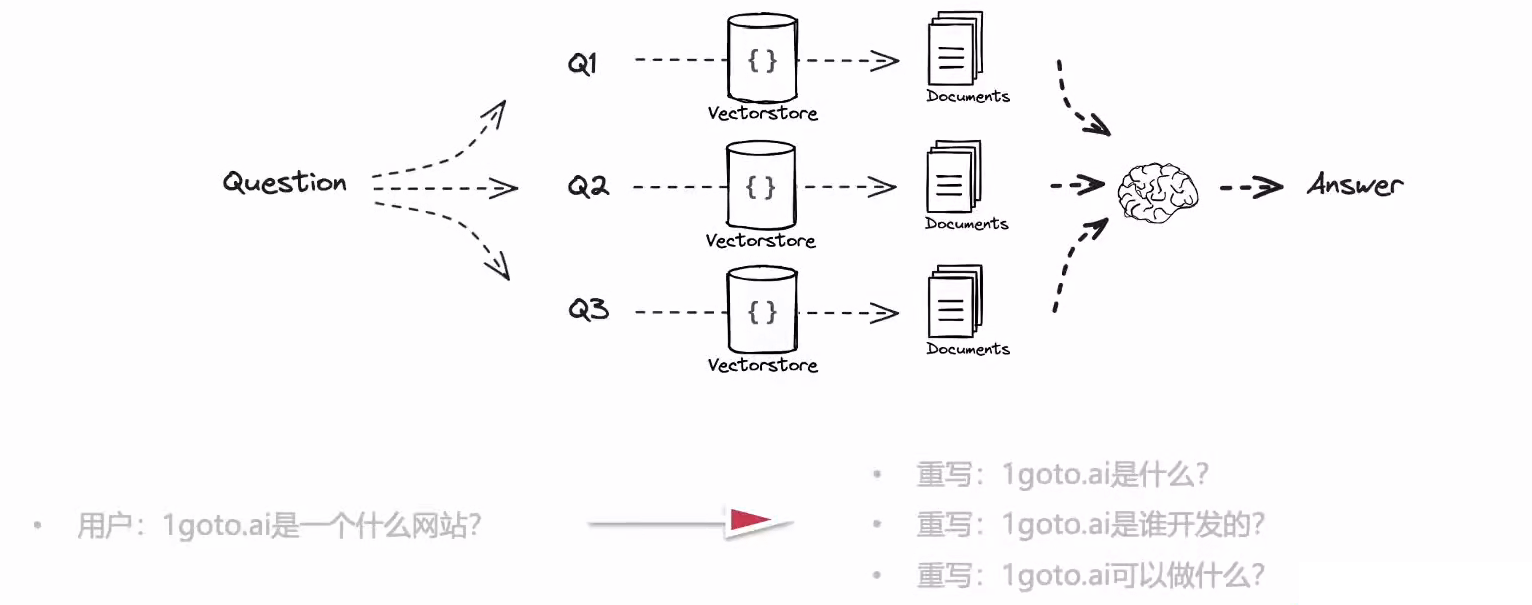


### 检索器：查询重写
---
- 使用多重查询来改写问题

通过大模型将用户的单一问题改写为多个不同角度、不同表述的问题，然后并行去向量数据库中检索，最后合并去重，从而大幅提高检索到相关文档的概率和准确性。

In [1]:
! pip install langchain_chroma

In [ ]:
# ================= 1. 导入必要的库 =================
from langchain_chroma import Chroma                                    # 导入 Chroma 向量数据库的 LangChain 集成
from langchain_openai import OpenAIEmbeddings                          # 导入兼容 OpenAI 接口的 Embedding（词向量）模型
from langchain_community.document_loaders import WebBaseLoader         # 导入用于抓取和加载网页内容的 Loader
from langchain_text_splitters import RecursiveCharacterTextSplitter    # 导入递归字符文本分割器（用于文本切块）
from langchain_classic.retrievers.multi_query import MultiQueryRetriever # 导入多查询检索器（用于查询扩展和去重）
from langchain_deepseek import ChatDeepSeek                            # 导入 DeepSeek 聊天模型（注：通常为第三方或自定义封装）
from dotenv import load_dotenv                                         # 用于加载 .env 文件中的环境变量
import logging                                                         # 用于配置和输出日志
import os                                                              # 用于读取系统环境变量

# ================= 2. 环境变量与 Embedding 模型初始化 =================
# 加载 .env 文件，读取其中配置的 API Key 和 Base URL 等敏感信息
load_dotenv()

# 初始化 Embedding 模型
# 这里利用 OpenAI 兼容接口，实际调用的是 Qwen 的 Embedding 模型
embeddings_model = OpenAIEmbeddings(
    model="Qwen/Qwen3-Embedding-8B",       # 指定使用的 Embedding 模型名称
    openai_api_key=os.getenv("api_key"),   # 从环境变量读取 API 密钥
    openai_api_base=os.getenv("base_url")  # 从环境变量读取 API 请求地址（兼容 OpenAI 格式的自定义端点）
)

# ================= 3. 数据摄取与处理 (Data Ingestion) =================
# 使用 WebBaseLoader 从指定的 URL 抓取网页内容
loader = WebBaseLoader("https://www.wenyanguji.com/book/71876/102284")
data = loader.load() # 执行加载，返回包含 Document 对象的列表（包含 page_content 和 metadata）

# 使用递归字符文本分割器将长网页文本切分成小块（Chunking）
# chunk_size=500: 每个文本块的最大字符数限制为 500
# chunk_overlap=0: 相邻文本块之间没有重叠字符（实际生产中通常建议设置 50-100 的重叠以保持上下文连贯）
text_splitter = RecursiveCharacterTextSplitter(chunk_size=500, chunk_overlap=0)
splits = text_splitter.split_documents(data) # 执行切分，得到多个短文本块

# ================= 4. 构建向量数据库 (Vector Database) =================
# 将切分后的文本块转换为高维向量，并存储到 Chroma 内存向量数据库中
# from_documents 会自动调用上面配置的 embeddings_model 将文本向量化并入库
vectordb = Chroma.from_documents(documents=splits, embedding=embeddings_model)

# ================= 5. 初始化 LLM 与多查询检索器 =================
# 初始化 DeepSeek 大语言模型，在这里它不直接回答用户问题，而是作为“查询改写器”使用
model = ChatDeepSeek(
    model="deepseek-ai/DeepSeek-V4.1-Flash", # 指定模型名称
    api_key=os.getenv("api_key"),            # API 密钥
    base_url=os.getenv("base_url"),          # API 请求地址
    temperature=0,                           # 温度设为 0，保证输出结果的确定性和稳定性，避免随机性
)

# 定义用户的原始查询问题
question = "如何让用户查询更准确？"

# 初始化 MultiQueryRetriever（多查询检索器）
# 核心原理：利用 LLM 将用户的单一问题改写为 3~5 个不同角度、不同表述的问题，
# 然后并行去向量数据库中检索，最后合并结果并去重，从而大幅提高检索的召回率（Recall）。
retriever_from_llm = MultiQueryRetriever.from_llm(
    retriever=vectordb.as_retriever(), # 底层使用刚才构建的 Chroma 向量数据库作为基础检索器
    llm=model                          # 使用 DeepSeek 模型作为查询改写的“大脑”
)

# ================= 6. 配置日志与执行检索 =================
# 配置日志级别为 INFO，这样可以在控制台直观地看到 LLM 到底生成了哪几个新的查询问题
logging.basicConfig()
logging.getLogger("langchain.retrievers.multi_query").setLevel(logging.INFO)

# 执行检索：传入原始问题
# 内部流程：1. LLM 改写问题 -> 2. 用多个新问题并行检索 -> 3. 合并结果并去除重复的 Document
unique_docs = retriever_from_llm.invoke(question)

# 打印最终检索到的唯一文档列表及其数量
print(unique_docs)
print(f"共检索到 {len(unique_docs)} 个不重复的相关文档片段。")

[Document(id='ea048891-cf08-4a17-8f42-0f0c1b899cb5', metadata={'language': 'en', 'source': 'https://python.langchain.com/docs/how_to/MultiQueryRetriever/', 'title': 'LangChain overview - Docs by LangChain', 'description': 'LangChain provides create_agent: a minimal, highly configurable agent harness. Compose exactly the agent your use case needs from model, tools, prompt, and middleware.'}, page_content='def get_weather(city: str) -> str:\n    """Get weather for a given city."""\n    return f"It\'s always sunny in {city}!"\n\nagent = create_agent(\n    model="openrouter:anthropic/claude-sonnet-4-6",\n    tools=[get_weather],\n    system_prompt="You are a helpful assistant",\n)'), Document(id='931e7c89-352d-40e6-95d6-90c51e12c0f4', metadata={'title': 'LangChain overview - Docs by LangChain', 'description': 'LangChain provides create_agent: a minimal, highly configurable agent harness. Compose exactly the agent your use case needs from model, tools, prompt, and middleware.', 'language': 